In [89]:
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score

In [90]:
data=pd.read_csv('Bank Customer Churn Prediction.csv')
data.head()

,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [91]:
data.shape

(10000, 12)

<Axes: xlabel='churn', ylabel='count'>

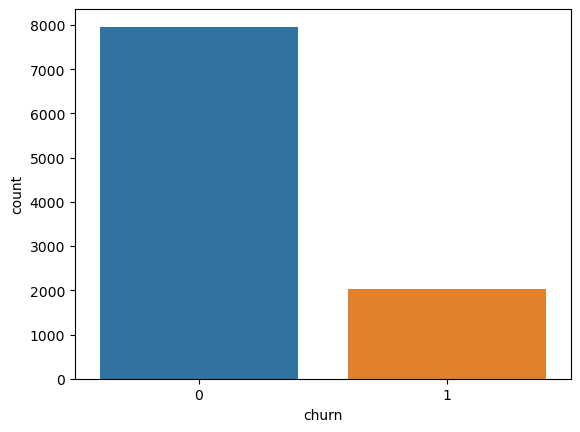

In [92]:
sns.countplot(x='churn',data=data)

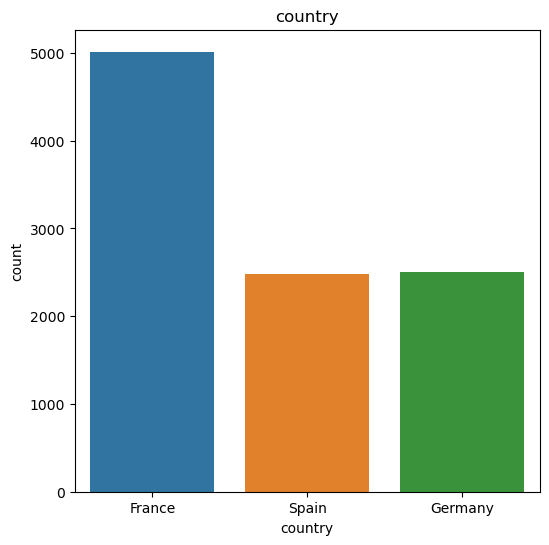

In [93]:
plt.figure(figsize=(6,6))

sns.countplot(x='country', data=data)

plt.title('country')
plt.show()

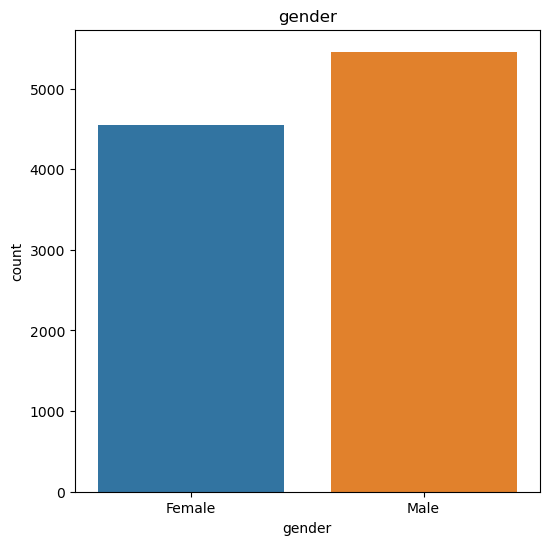

In [94]:
plt.figure(figsize=(6,6))

sns.countplot(x='gender', data=data)

plt.title('gender')
plt.show()

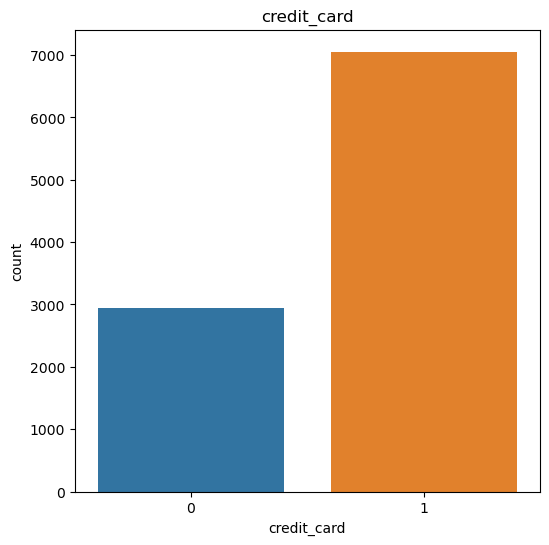

In [95]:
plt.figure(figsize=(6,6))

sns.countplot(x='credit_card', data=data)

plt.title('credit_card')
plt.show()

C:\Users\mero1\AppData\Local\Temp\ipykernel_11476\3930268708.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data['credit_score'])
C:\anaconda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


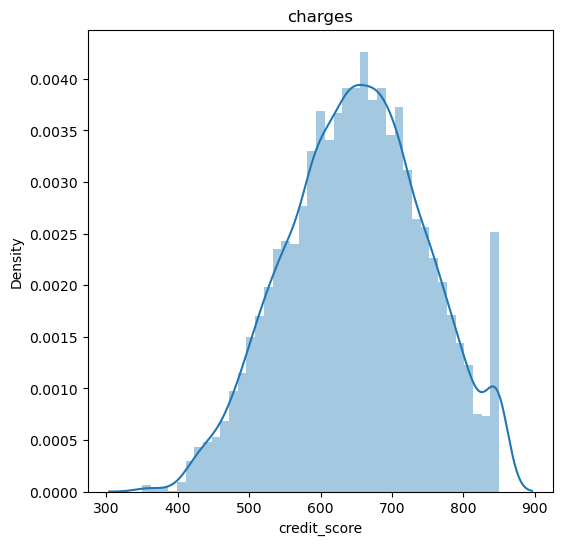

In [96]:
plt.figure(figsize=(6,6))

sns.distplot(data['credit_score'])

plt.title('charges')
plt.show()

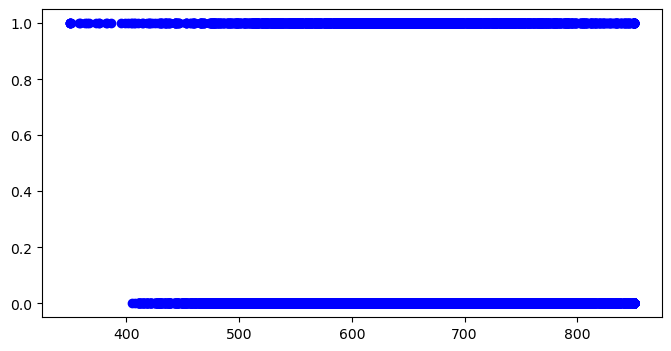

In [97]:
plt.figure(figsize=(8, 4))
plt.scatter(data['credit_score'], data['churn'], color='b')

plt.show()

In [98]:
data.isnull().sum()

customer_id         0
credit_score        0
country             0
gender              0
age                 0
tenure              0
balance             0
products_number     0
credit_card         0
active_member       0
estimated_salary    0
churn               0
dtype: int64

In [99]:
label_encoder = LabelEncoder()

data['gender']=label_encoder.fit_transform(data['gender'])
data.head()

,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,0,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,0,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,0,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,0,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,0,43,2,125510.82,1,1,1,79084.10,0


In [100]:
data.country.value_counts()

country
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [101]:
data = pd.get_dummies(data, columns=['country']).astype(int)
data.head()


,customer_id,credit_score,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn,country_France,country_Germany,country_Spain
0,15634602,619,0,42,2,0,1,1,1,101348,1,1,0,0
1,15647311,608,0,41,1,83807,1,0,1,112542,0,0,0,1
2,15619304,502,0,42,8,159660,3,1,0,113931,1,1,0,0
3,15701354,699,0,39,1,0,2,0,0,93826,0,1,0,0
4,15737888,850,0,43,2,125510,1,1,1,79084,0,0,0,1


In [102]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   customer_id       10000 non-null  int32
 1   credit_score      10000 non-null  int32
 2   gender            10000 non-null  int32
 3   age               10000 non-null  int32
 4   tenure            10000 non-null  int32
 5   balance           10000 non-null  int32
 6   products_number   10000 non-null  int32
 7   credit_card       10000 non-null  int32
 8   active_member     10000 non-null  int32
 9   estimated_salary  10000 non-null  int32
 10  churn             10000 non-null  int32
 11  country_France    10000 non-null  int32
 12  country_Germany   10000 non-null  int32
 13  country_Spain     10000 non-null  int32
dtypes: int32(14)
memory usage: 547.0 KB


In [103]:
data=data.drop(['customer_id'], axis=1)
data.head()

,credit_score,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn,country_France,country_Germany,country_Spain
0,619,0,42,2,0,1,1,1,101348,1,1,0,0
1,608,0,41,1,83807,1,0,1,112542,0,0,0,1
2,502,0,42,8,159660,3,1,0,113931,1,1,0,0
3,699,0,39,1,0,2,0,0,93826,0,1,0,0
4,850,0,43,2,125510,1,1,1,79084,0,0,0,1


In [104]:
x=data.drop(['churn' ], axis=1)

y=data['churn']

In [105]:
x_train,x_test, y_train,y_test = train_test_split(x,y,test_size=0.2, random_state=42)

In [106]:
model= LogisticRegression()
model.fit(x_train, y_train)

LogisticRegression()

In [107]:
y_predicted =model.predict(x_test)
y_predicted

array([0, 0, 0, ..., 0, 0, 0])

In [108]:
accuracy=accuracy_score( y_predected, y_test)
accuracy

0.8005

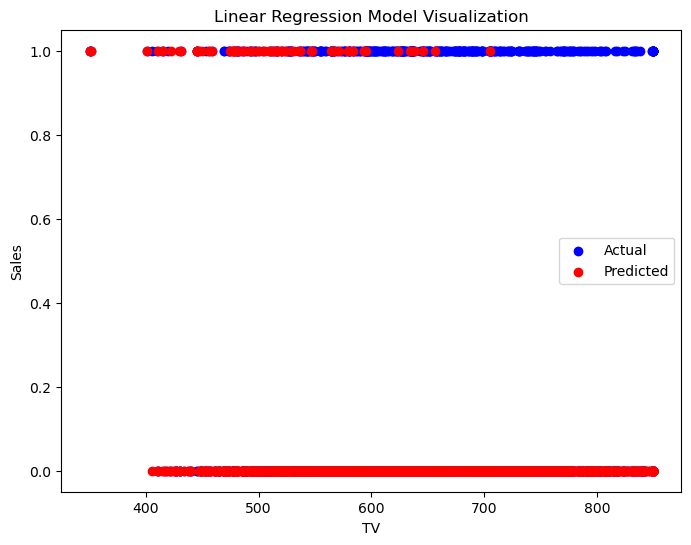

In [111]:
plt.figure(figsize=(8, 6))
plt.scatter(x_test['credit_score'], y_test, color='blue', label='Actual')

plt.scatter(x_test['credit_score'], y_predected, color='red', label='Predicted')

plt.xlabel('TV')
plt.ylabel('Sales')
plt.title('Linear Regression Model Visualization')
plt.legend()
plt.show()